# Stoploss tape analysis

Same DuckDB + `httpfs` + Seaweed setup as `analyze.ipynb`.

Reads **every** position under `{ledger}/stoploss/**` (legacy flood) or `{ledger}/stops/**` (lifecycle beats), not only rows that already fired a `TriggerReason`.

Against the real flood, keep `SNAPSHOT=True` — lazy `read_json('…/**')` will not reliably scan hundreds of thousands of tiny objects per query.


In [21]:
%pip install -q duckdb polars pandas pyarrow seaborn matplotlib


Note: you may need to restart the kernel to use updated packages.


In [22]:
import duckdb
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

BUCKET = "symm"
LEDGER = "real"  # paper | real | virtual
ENDPOINT = "s3.seaweed.home.arpa"

try:
    con.close()
except Exception:
    pass

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("SET unsafe_disable_etag_checks=true;")
con.execute(f"""
CREATE OR REPLACE SECRET seaweed_s3 (
    TYPE S3,
    KEY_ID 'anonymous',
    SECRET 'anonymous',
    REGION 'us-east-1',
    ENDPOINT '{ENDPOINT}',
    URL_STYLE 'path',
    USE_SSL false
);
""")

# New writers use stops/; this cluster still has the pre-rename real/stoploss/ flood.
STOPS_PREFIX = "stops"
try:
    con.execute(
        f"SELECT 1 FROM read_json('s3://{BUCKET}/{LEDGER}/stops/**', filename=true, union_by_name=true) LIMIT 1"
    ).fetchone()
except Exception as err:
    if "No files found" not in str(err):
        raise
    STOPS_PREFIX = "stoploss"

STOPS_GLOB = f"s3://{BUCKET}/{LEDGER}/{STOPS_PREFIX}/**"
CLOSED_GLOB = f"s3://{BUCKET}/{LEDGER}/closed/**"
OPEN_GLOB = f"s3://{BUCKET}/{LEDGER}/open/**"
print("stops:", STOPS_GLOB)
print("open:", OPEN_GLOB)
print("closed:", CLOSED_GLOB)


stops: s3://symm/real/stops/**
open: s3://symm/real/open/**
closed: s3://symm/real/closed/**


## Snapshot the tape once

Required for `real/stoploss/` (200k+ tiny objects). After this, every query hits a local table.


In [23]:
SNAPSHOT = True  # keep True on real/stoploss flood
SNAP_PATH = f"/tmp/symm_stops_{LEDGER}.duckdb"
FORCE_RESNAP = False  # True to rebuild even if file exists

STOPS_COLUMNS = """{
    'State': 'INTEGER',
    'Regime': 'VARCHAR',
    'InitialPnLPct': 'DOUBLE',
    'CurrentPnLPct': 'DOUBLE',
    'PeakPnLPct': 'DOUBLE',
    'ArmPnlPct': 'DOUBLE',
    'TrailingFloor': 'DOUBLE',
    'ExhaustScore': 'DOUBLE',
    'Confirms': 'INTEGER',
    'TypicalPush': 'DOUBLE',
    'TypicalPullback': 'DOUBLE',
    'CurrentDrop': 'DOUBLE',
    'EmaDelta': 'DOUBLE',
    'TriggerReason': 'VARCHAR',
    'ExplosiveActive': 'BOOLEAN',
    'ExplosivePushes': 'INTEGER',
    'PeakPushDelta': 'DOUBLE'
}"""

path_re = "/" + STOPS_PREFIX + "/(.+)/([^/]+)/([0-9]{19})$"

def stops_select_sql(glob: str) -> str:
    return """
SELECT
    regexp_extract(filename, '__PATH_RE__', 1) AS symbol,
    regexp_extract(filename, '__PATH_RE__', 2) AS position_id,
    TRY_CAST(regexp_extract(filename, '__PATH_RE__', 3) AS UBIGINT) AS noted_at_ns,
    State AS state,
    Regime AS regime,
    InitialPnLPct AS initial_pnl_pct,
    CurrentPnLPct AS current_pnl_pct,
    PeakPnLPct AS peak_pnl_pct,
    ArmPnlPct AS arm_pnl_pct,
    TrailingFloor AS trailing_floor,
    ExhaustScore AS exhaust_score,
    Confirms AS confirms,
    TypicalPush AS typical_push,
    TypicalPullback AS typical_pullback,
    CurrentDrop AS current_drop,
    EmaDelta AS ema_delta,
    COALESCE(TriggerReason, '') AS trigger_reason,
    (PeakPnLPct - CurrentPnLPct) AS giveback_pct,
    ExplosiveActive AS explosive_active,
    ExplosivePushes AS explosive_pushes,
    PeakPushDelta AS peak_push_delta
FROM read_json(
    '__GLOB__',
    filename=true,
    union_by_name=true,
    columns=__COLUMNS__
)
""".replace("__PATH_RE__", path_re).replace("__GLOB__", glob).replace("__COLUMNS__", STOPS_COLUMNS)

import os
if SNAPSHOT:
    if FORCE_RESNAP or not os.path.exists(SNAP_PATH):
        snap = duckdb.connect(SNAP_PATH)
        snap.execute("INSTALL httpfs; LOAD httpfs;")
        snap.execute("SET unsafe_disable_etag_checks=true;")
        snap.execute(f"""
        CREATE OR REPLACE SECRET seaweed_s3 (
            TYPE S3, KEY_ID 'anonymous', SECRET 'anonymous',
            REGION 'us-east-1', ENDPOINT '{ENDPOINT}',
            URL_STYLE 'path', USE_SSL false
        );
        """)
        print("snapshotting", STOPS_GLOB, "→", SNAP_PATH, "(slow once)…")
        snap.execute("CREATE OR REPLACE TABLE stops AS " + stops_select_sql(STOPS_GLOB))
        n = snap.execute("SELECT count(*), count(DISTINCT position_id) FROM stops").fetchone()
        print("beats:", n[0], "positions:", n[1])
        snap.close()
    else:
        print("reusing snapshot:", SNAP_PATH)
    con.close()
    con = duckdb.connect(SNAP_PATH)
    STOPS_FROM = "stops"
else:
    STOPS_FROM = "(" + stops_select_sql(STOPS_GLOB) + ")"
    print("lazy S3 source:", STOPS_GLOB)


snapshotting s3://symm/real/stops/** → /tmp/symm_stops_real.duckdb (slow once)…
beats: 781 positions: 21


## Census — every position (latest beat)

One row per `position_id`, whether or not it has fired.


In [24]:
positions_sql = f"""
WITH beats AS (
    SELECT * FROM {STOPS_FROM}
),
latest AS (
    SELECT *
    FROM beats
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY position_id ORDER BY noted_at_ns DESC
    ) = 1
)
SELECT
    symbol,
    position_id,
    state,
    regime,
    trigger_reason,
    round(peak_pnl_pct, 3) AS peak_pnl_pct,
    round(current_pnl_pct, 3) AS current_pnl_pct,
    round(trailing_floor, 3) AS trailing_floor,
    round(giveback_pct, 3) AS giveback_pct,
    confirms,
    noted_at_ns
FROM latest
ORDER BY noted_at_ns DESC;
"""

df_positions = con.sql(positions_sql).pl()
print("positions:", df_positions.height)
df_positions


positions: 21


symbol,position_id,state,regime,trigger_reason,peak_pnl_pct,current_pnl_pct,trailing_floor,giveback_pct,confirms,noted_at_ns
str,str,i32,str,str,f64,f64,f64,f64,i32,u64
"""VINE/USD""","""3e5b941f-0260-4529-8076-04423b…",0,"""SMOOTH""","""""",-25.968,-31.48,0.722,5.511,0,1794835294503651000
"""SKR/USD""","""eca9711b-6242-47e1-9810-b7dd55…",0,"""SMOOTH""","""""",-16.905,-17.586,0.794,0.681,0,1794835290554997000
"""XDC/USD""","""5c435d66-cb04-4595-8d8e-9f9c4f…",0,"""SMOOTH""","""""",-4.95,-5.114,0.013,0.164,0,1794835262960125000
"""BAL/USD""","""0b42f311-8a0a-40e2-83d9-6cdb52…",0,"""CHAOS""","""""",-5.855,-6.356,0.014,0.501,0,1794835193671804000
"""ZEC/USD""","""46516b1f-90fa-4003-8d63-ff6bc7…",0,"""CRAWL""","""""",-13.181,-13.591,0.01,0.41,0,1794834950087287000
…,…,…,…,…,…,…,…,…,…,…
"""BAL/USD""","""d942a9e9-c4e3-4852-968f-0edbcf…",0,"""SMOOTH""","""""",-5.521,-5.772,0.019,0.25,0,1794825127407984000
"""AVAX/USD""","""bb6aeac2-87a5-4caa-b0fb-4beeb6…",0,"""CRAWL""","""""",-3.234,-3.234,0.01,0.0,0,1794825126159207000
"""DOGE/USD""","""d0e87b8d-0f6f-49d8-8aee-2553c1…",0,"""CRAWL""","""""",-3.161,-3.161,0.011,0.0,0,1794825124137154000


## Triggered only

Subset where the stop actually tripped (`state = 2` or non-empty `trigger_reason`).


In [25]:
triggers_sql = f"""
WITH beats AS (
    SELECT * FROM {STOPS_FROM}
),
fired AS (
    SELECT *
    FROM beats
    WHERE state = 2 OR (trigger_reason IS NOT NULL AND trigger_reason <> '')
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY position_id ORDER BY noted_at_ns DESC
    ) = 1
)
SELECT
    trigger_reason,
    regime,
    count(*) AS n,
    round(avg(peak_pnl_pct), 3) AS avg_peak,
    round(avg(current_pnl_pct), 3) AS avg_exit,
    round(avg(giveback_pct), 3) AS avg_giveback
FROM fired
GROUP BY 1, 2
ORDER BY n DESC;
"""

df_triggers = con.sql(triggers_sql).pl()
df_triggers


trigger_reason,regime,n,avg_peak,avg_exit,avg_giveback
str,str,i64,f64,f64,f64


In [26]:
fired_sql = f"""
WITH beats AS (
    SELECT * FROM {STOPS_FROM}
),
fired AS (
    SELECT *
    FROM beats
    WHERE state = 2 OR (trigger_reason IS NOT NULL AND trigger_reason <> '')
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY position_id ORDER BY noted_at_ns DESC
    ) = 1
)
SELECT
    symbol,
    position_id,
    trigger_reason,
    regime,
    round(peak_pnl_pct, 3) AS peak_pnl_pct,
    round(current_pnl_pct, 3) AS stop_pnl_pct,
    round(giveback_pct, 3) AS giveback_pct,
    noted_at_ns
FROM fired
ORDER BY noted_at_ns DESC;
"""

df_fired = con.sql(fired_sql).pl()
print("triggered positions:", df_fired.height)
df_fired


triggered positions: 0


symbol,position_id,trigger_reason,regime,peak_pnl_pct,stop_pnl_pct,giveback_pct,noted_at_ns
str,str,str,str,f64,f64,f64,u64


In [27]:
if df_fired.height:
    pdf = df_fired.to_pandas()
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.boxplot(data=pdf, x="trigger_reason", y="giveback_pct", ax=ax)
    ax.tick_params(axis="x", rotation=30)
    ax.set_title(f"Giveback by trigger — {LEDGER} (n={df_fired.height})")
    ax.axhline(0, color="gray", ls=":", alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("no triggered rows in tape yet")


no triggered rows in tape yet


## All position trajectories

One chart per `position_id` in `df_positions` (latest-beat census). Dense floods are downsampled for plotting.


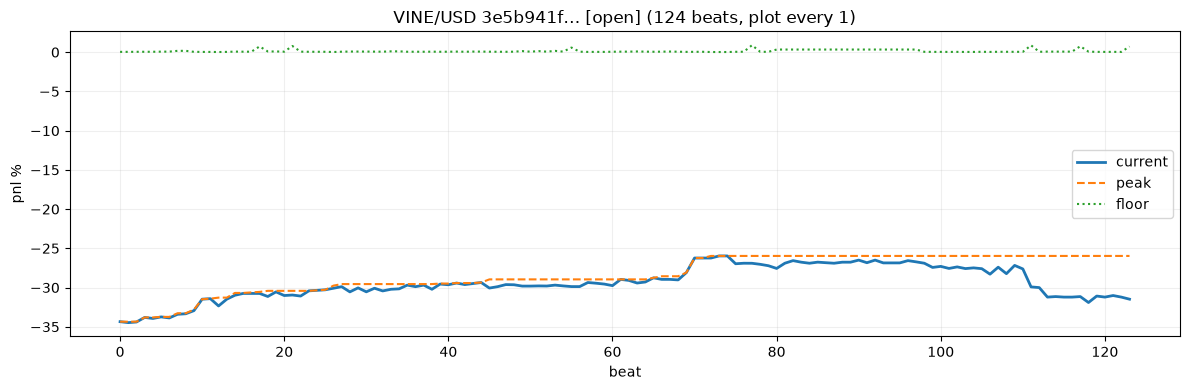

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""VINE/USD""",1794834903726304000,0,"""CHAOS""",-27.489542,-25.968405,0.032708,"""""",0
"""VINE/USD""",1794834966996117000,0,"""EXPLOSIVE""",-27.593057,-25.968405,0.048806,"""""",0
"""VINE/USD""",1794834967031281000,0,"""CHAOS""",-28.292368,-25.968405,0.033385,"""""",0
"""VINE/USD""",1794834967031366000,0,"""EXPLOSIVE""",-27.402336,-25.968405,0.048795,"""""",0
"""VINE/USD""",1794834967088882000,0,"""CHAOS""",-28.228794,-25.968405,0.048795,"""""",0
…,…,…,…,…,…,…,…,…
"""VINE/USD""",1794835269621443000,0,"""SMOOTH""",-31.081123,-25.968405,0.039398,"""""",0
"""VINE/USD""",1794835269621506000,0,"""CHAOS""",-31.213921,-25.968405,0.036132,"""""",0
"""VINE/USD""",1794835269624884000,0,"""SMOOTH""",-31.014724,-25.968405,0.039434,"""""",0


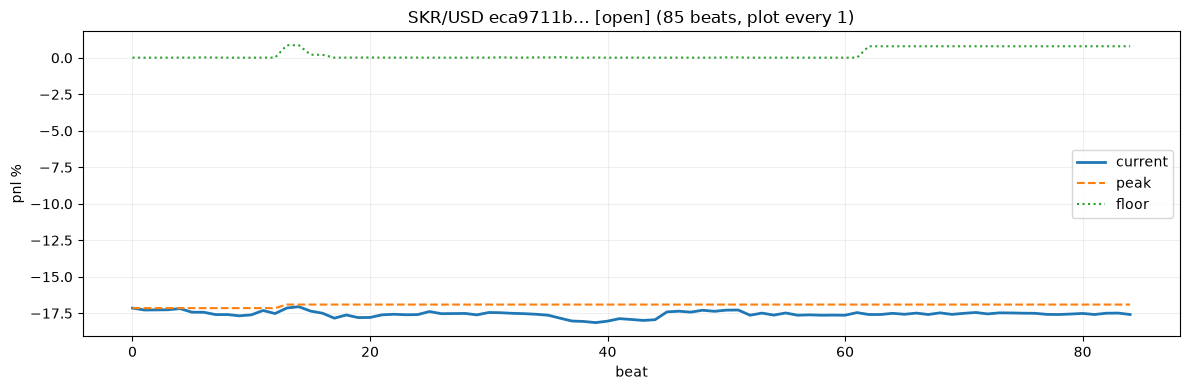

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""SKR/USD""",1794834963245118000,0,"""CRAWL""",-17.569704,-16.90464,0.794369,"""""",0
"""SKR/USD""",1794834963247977000,0,"""SMOOTH""",-17.488599,-16.90464,0.794369,"""""",0
"""SKR/USD""",1794835051576224000,0,"""CRAWL""",-17.585925,-16.90464,0.794369,"""""",0
"""SKR/USD""",1794835065310790000,0,"""SMOOTH""",-17.472378,-16.90464,0.794369,"""""",0
"""SKR/USD""",1794835085278710000,0,"""CRAWL""",-17.577815,-16.90464,0.794369,"""""",0
…,…,…,…,…,…,…,…,…
"""SKR/USD""",1794835289028214000,0,"""SMOOTH""",-17.51293,-16.90464,0.794369,"""""",0
"""SKR/USD""",1794835289197184000,0,"""CRAWL""",-17.585925,-16.90464,0.794369,"""""",0
"""SKR/USD""",1794835289653706000,0,"""SMOOTH""",-17.496709,-16.90464,0.794369,"""""",0


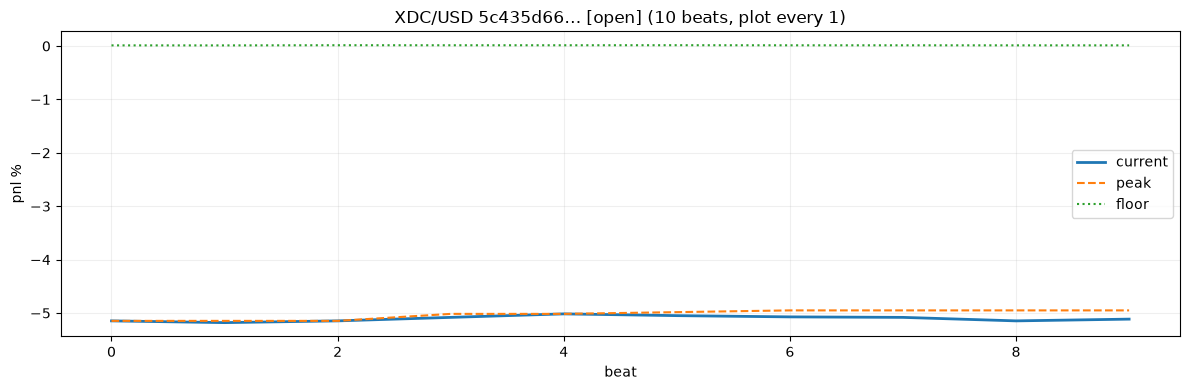

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""XDC/USD""",1794834151303577000,0,"""CRAWL""",-5.146603,-5.146603,0.012262,"""""",0
"""XDC/USD""",1794834166077570000,0,"""SMOOTH""",-5.179339,-5.146603,0.011723,"""""",0
"""XDC/USD""",1794834371003447000,0,"""CHAOS""",-5.146603,-5.146603,0.015034,"""""",0
"""XDC/USD""",1794834756762877000,0,"""SMOOTH""",-5.081132,-5.015661,0.014248,"""""",0
"""XDC/USD""",1794834896620805000,0,"""CHAOS""",-5.015661,-5.015661,0.014323,"""""",0
"""XDC/USD""",1794834972841785000,0,"""SMOOTH""",-5.048396,-4.982925,0.015373,"""""",0
"""XDC/USD""",1794835147591406000,0,"""CHAOS""",-5.071758,-4.95019,0.013544,"""""",0
"""XDC/USD""",1794835147631162000,0,"""SMOOTH""",-5.081132,-4.95019,0.013586,"""""",0
"""XDC/USD""",1794835233567242000,0,"""CHAOS""",-5.146603,-4.95019,0.012816,"""""",0


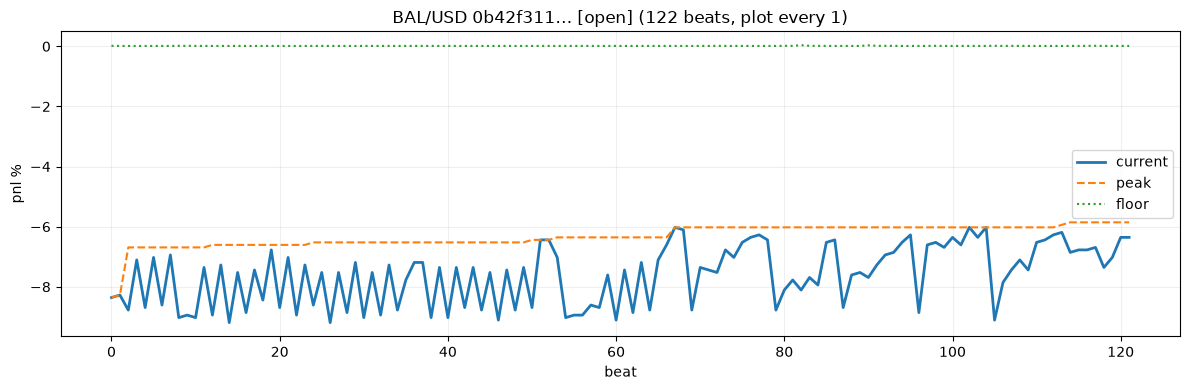

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""BAL/USD""",1794834991333840000,0,"""SMOOTH""",-6.021915,-6.021915,0.013699,"""""",0
"""BAL/USD""",1794834992437732000,0,"""CHAOS""",-6.355641,-6.021915,0.012602,"""""",0
"""BAL/USD""",1794834994202810000,0,"""SMOOTH""",-6.021915,-6.021915,0.013417,"""""",0
"""BAL/USD""",1794834999062808000,0,"""CHAOS""",-9.108878,-6.021915,0.018567,"""""",0
"""BAL/USD""",1794835001989102000,0,"""SMOOTH""",-7.857406,-6.021915,0.013528,"""""",0
…,…,…,…,…,…,…,…,…
"""BAL/USD""",1794835077320323000,0,"""CHAOS""",-6.689367,-5.855053,0.017669,"""""",0
"""BAL/USD""",1794835078470815000,0,"""SMOOTH""",-7.356818,-5.855053,0.013532,"""""",0
"""BAL/USD""",1794835080199282000,0,"""CHAOS""",-7.023092,-5.855053,0.013619,"""""",0


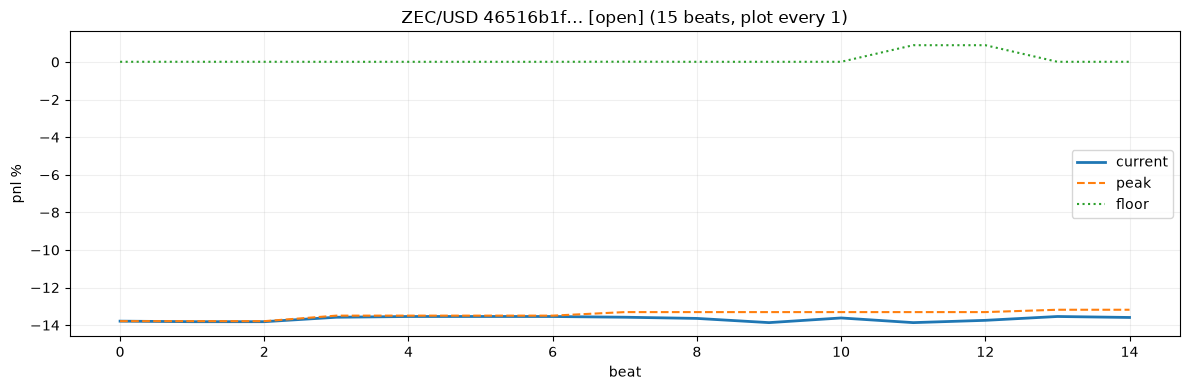

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""ZEC/USD""",1794834133221266000,0,"""CRAWL""",-13.788046,-13.788046,0.010761,"""""",0
"""ZEC/USD""",1794834133613009000,0,"""SMOOTH""",-13.816533,-13.788046,0.011234,"""""",0
"""ZEC/USD""",1794834133613065000,0,"""CRAWL""",-13.816524,-13.788046,0.011092,"""""",0
"""ZEC/USD""",1794834202192867000,0,"""SMOOTH""",-13.579341,-13.494237,0.010049,"""""",0
"""ZEC/USD""",1794834202348226000,0,"""CRAWL""",-13.540842,-13.494237,0.010072,"""""",0
…,…,…,…,…,…,…,…,…
"""ZEC/USD""",1794834218251634000,0,"""CHAOS""",-13.61784,-13.305795,0.01005,"""""",0
"""ZEC/USD""",1794834218298990000,0,"""SMOOTH""",-13.866057,-13.305795,0.892615,"""""",0
"""ZEC/USD""",1794834218605492000,0,"""CRAWL""",-13.744481,-13.305795,0.892615,"""""",0


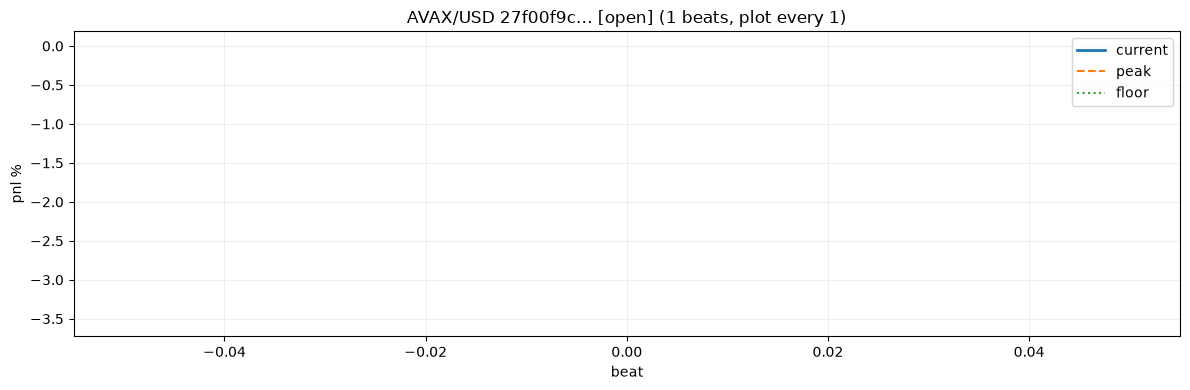

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""AVAX/USD""",1794834135250035000,0,"""CRAWL""",-3.549871,-3.549871,0.010084,"""""",0


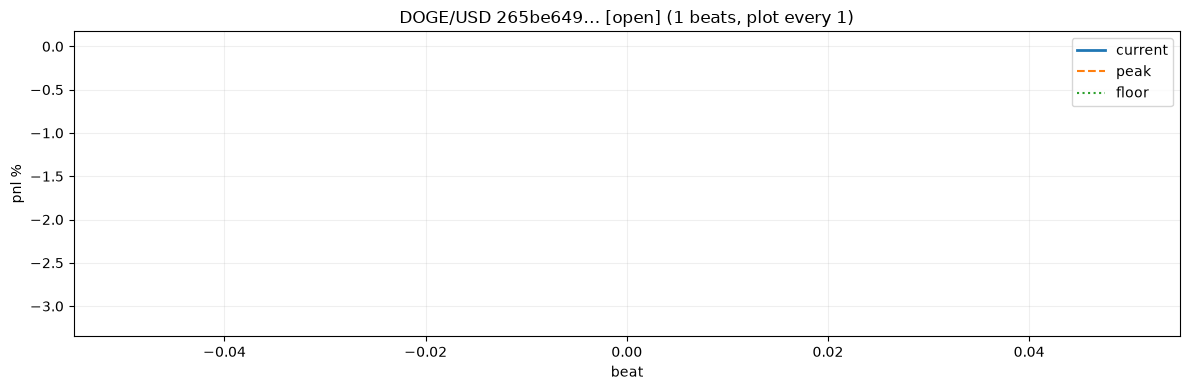

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""DOGE/USD""",1794834133291247000,0,"""CRAWL""",-3.190693,-3.190693,0.013382,"""""",0


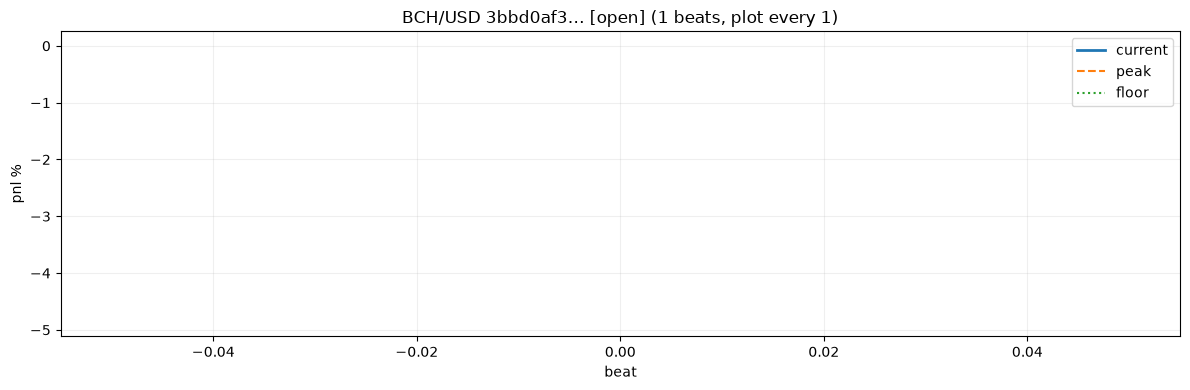

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""BCH/USD""",1794834133233909000,0,"""CRAWL""",-4.872399,-4.872399,0.011041,"""""",0


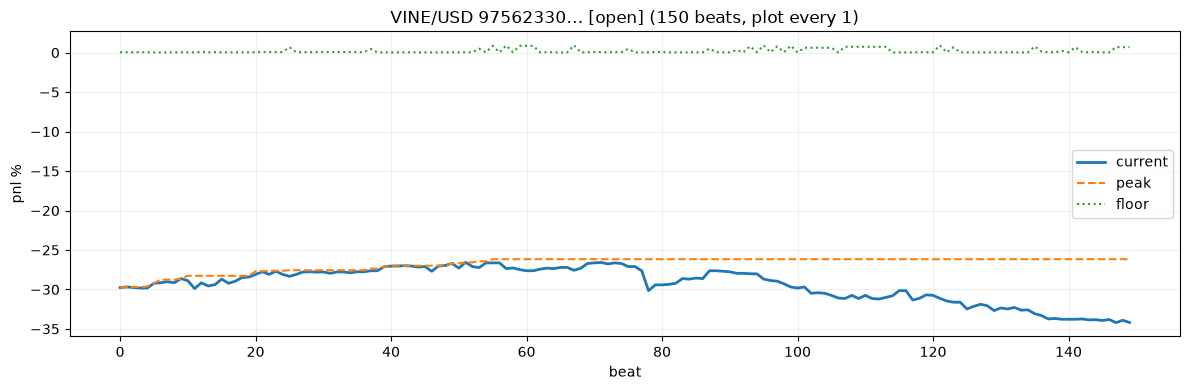

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""VINE/USD""",1794827798260813000,0,"""CHAOS""",-32.342703,-26.167602,0.0393,"""""",0
"""VINE/USD""",1794827798456421000,0,"""SMOOTH""",-32.475501,-26.167602,0.044229,"""""",0
"""VINE/USD""",1794827798457758000,0,"""CHAOS""",-32.276304,-26.167602,0.046389,"""""",0
"""VINE/USD""",1794827874125315000,0,"""SMOOTH""",-32.625783,-26.167602,0.024206,"""""",0
"""VINE/USD""",1794827874125447000,0,"""CHAOS""",-32.583841,-26.167602,0.023655,"""""",0
…,…,…,…,…,…,…,…,…
"""VINE/USD""",1794828060742750000,0,"""SMOOTH""",-33.930828,-26.167602,0.034112,"""""",0
"""VINE/USD""",1794828060742821000,0,"""CHAOS""",-33.803479,-26.167602,0.03178,"""""",0
"""VINE/USD""",1794828060959501000,0,"""SMOOTH""",-34.201873,-26.167602,0.699194,"""""",0


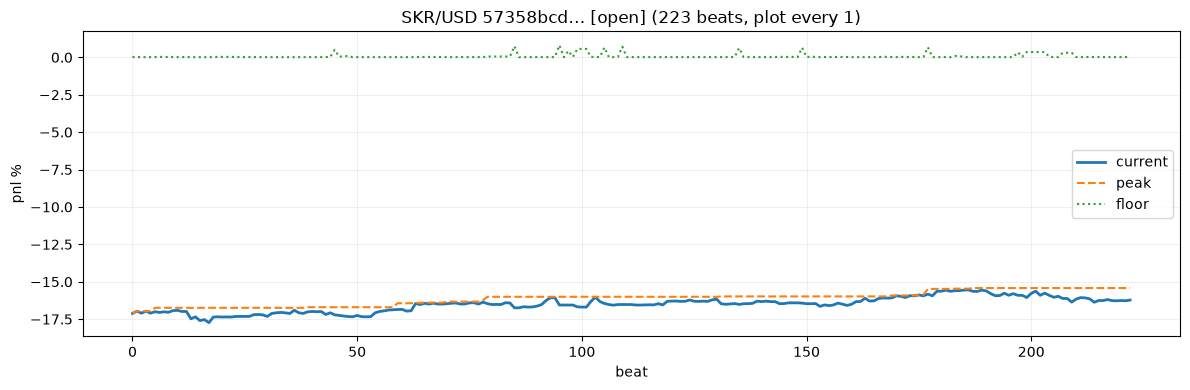

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""SKR/USD""",1794827877700701000,0,"""SMOOTH""",-15.761055,-15.420413,0.354682,"""""",0
"""SKR/USD""",1794827879525459000,0,"""CHAOS""",-15.907045,-15.420413,0.038172,"""""",0
"""SKR/USD""",1794827885430080000,0,"""SMOOTH""",-16.036813,-15.420413,0.020309,"""""",0
"""SKR/USD""",1794827885431780000,0,"""CHAOS""",-15.971929,-15.420413,0.018056,"""""",0
"""SKR/USD""",1794827909366137000,0,"""SMOOTH""",-16.117919,-15.420413,0.303313,"""""",0
…,…,…,…,…,…,…,…,…
"""SKR/USD""",1794828042962041000,0,"""CHAOS""",-16.263908,-15.420413,0.012897,"""""",0
"""SKR/USD""",1794828046476274000,0,"""SMOOTH""",-16.272019,-15.420413,0.013091,"""""",0
"""SKR/USD""",1794828047198068000,0,"""CHAOS""",-16.255798,-15.420413,0.013835,"""""",0


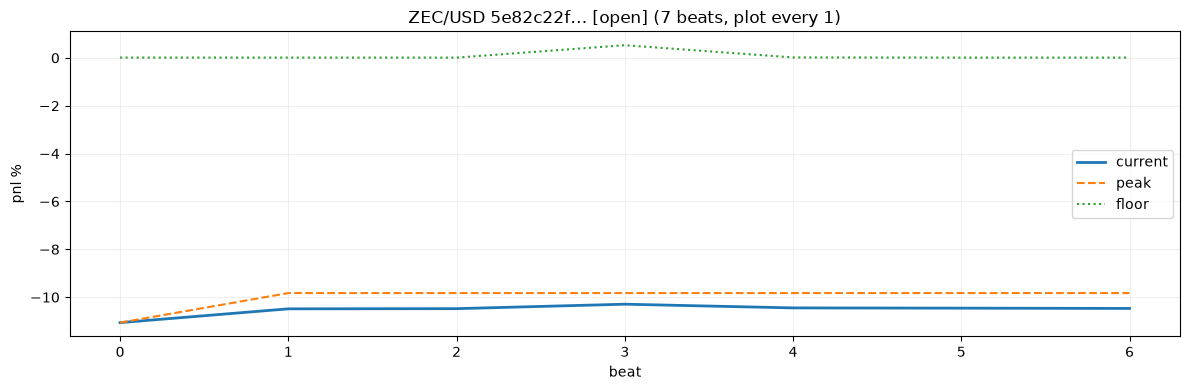

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""ZEC/USD""",1794825201655051000,0,"""CRAWL""",-11.062717,-11.062717,0.011412,"""""",0
"""ZEC/USD""",1794827926238411000,0,"""SMOOTH""",-10.486244,-9.827707,0.011208,"""""",0
"""ZEC/USD""",1794827926512814000,0,"""CRAWL""",-10.479152,-9.827707,0.010238,"""""",0
"""ZEC/USD""",1794827974767057000,0,"""SMOOTH""",-10.292736,-9.827707,0.528466,"""""",0
"""ZEC/USD""",1794827974816873000,0,"""CHAOS""",-10.447837,-9.827707,0.017208,"""""",0
"""ZEC/USD""",1794827974924251000,0,"""SMOOTH""",-10.45795,-9.827707,0.01099,"""""",0
"""ZEC/USD""",1794827975096098000,0,"""CRAWL""",-10.470034,-9.827707,0.010119,"""""",0


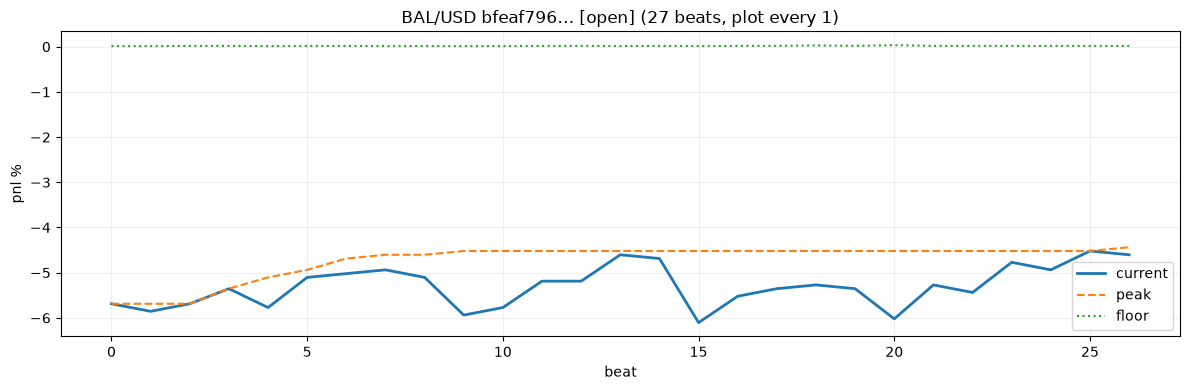

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""BAL/USD""",1794825905145576000,0,"""SMOOTH""",-4.937307,-4.603581,0.014142,"""""",0
"""BAL/USD""",1794825907899127000,0,"""CHAOS""",-5.10417,-4.603581,0.014635,"""""",0
"""BAL/USD""",1794826788614345000,0,"""SMOOTH""",-5.938484,-4.52015,0.01294,"""""",0
"""BAL/USD""",1794826788689975000,0,"""CHAOS""",-5.771621,-4.52015,0.014067,"""""",0
"""BAL/USD""",1794826809842549000,0,"""SMOOTH""",-5.187601,-4.52015,0.017403,"""""",0
…,…,…,…,…,…,…,…,…
"""BAL/USD""",1794827584051370000,0,"""CHAOS""",-5.437895,-4.52015,0.018909,"""""",0
"""BAL/USD""",1794827596146492000,0,"""SMOOTH""",-4.770444,-4.52015,0.017733,"""""",0
"""BAL/USD""",1794827611243169000,0,"""CHAOS""",-4.937307,-4.52015,0.018342,"""""",0


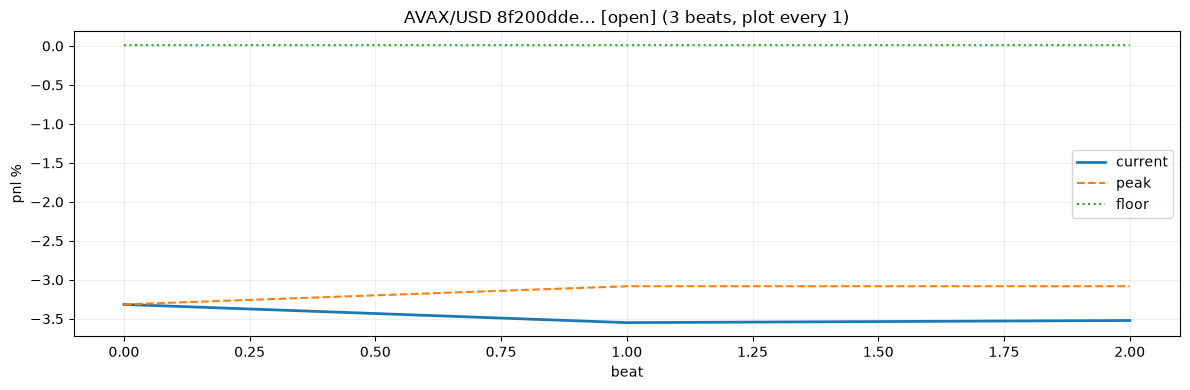

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""AVAX/USD""",1794825203681524000,0,"""CRAWL""",-3.316427,-3.316427,0.010071,"""""",0
"""AVAX/USD""",1794825386050099000,0,"""SMOOTH""",-3.549871,-3.082983,0.010059,"""""",0
"""AVAX/USD""",1794825386814454000,0,"""CRAWL""",-3.522407,-3.082983,0.010109,"""""",0


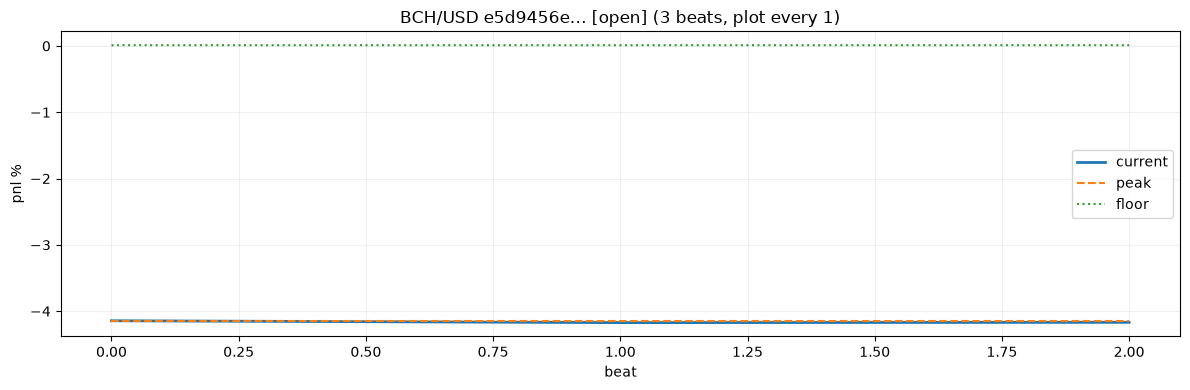

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""BCH/USD""",1794825201661403000,0,"""CRAWL""",-4.144678,-4.144678,0.010752,"""""",0
"""BCH/USD""",1794825203738366000,0,"""SMOOTH""",-4.172848,-4.144678,0.010712,"""""",0
"""BCH/USD""",1794825203793207000,0,"""CRAWL""",-4.168153,-4.144678,0.010825,"""""",0


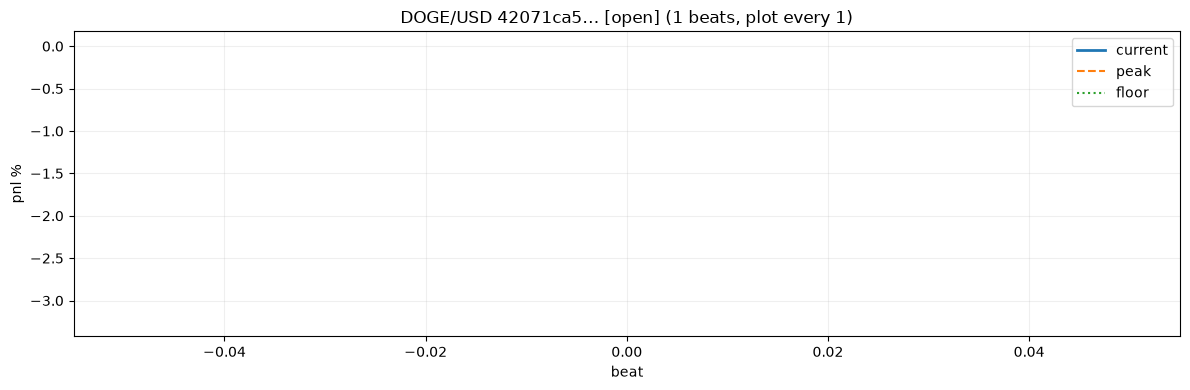

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""DOGE/USD""",1794825201703087000,0,"""CRAWL""",-3.260188,-3.260188,0.01156,"""""",0


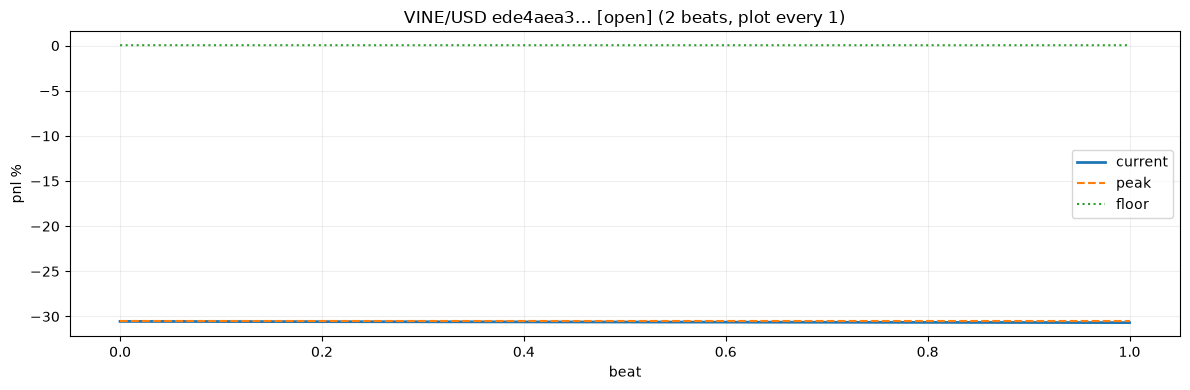

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""VINE/USD""",1794825136473081000,0,"""CRAWL""",-30.549932,-30.549932,0.04411,"""""",0
"""VINE/USD""",1794825136636418000,0,"""SMOOTH""",-30.68273,-30.549932,0.041295,"""""",0


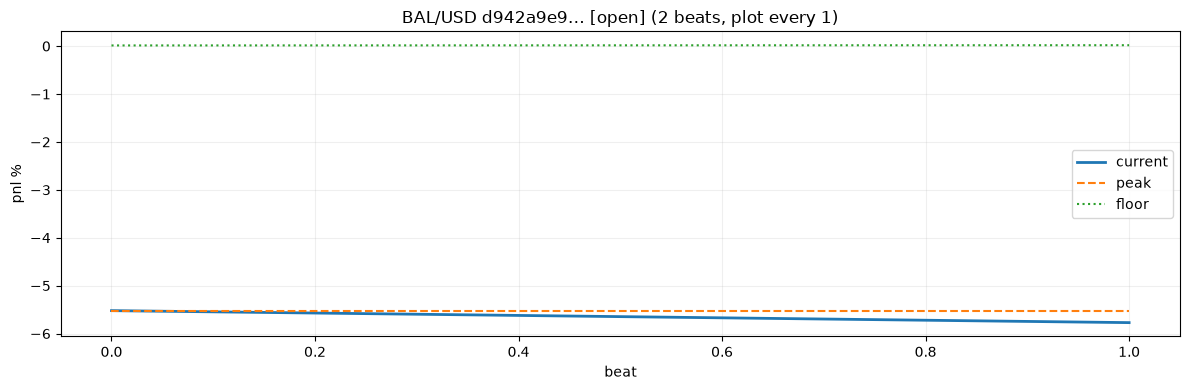

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""BAL/USD""",1794825124087064000,0,"""CRAWL""",-5.521327,-5.521327,0.013845,"""""",0
"""BAL/USD""",1794825127407984000,0,"""SMOOTH""",-5.771621,-5.521327,0.018806,"""""",0


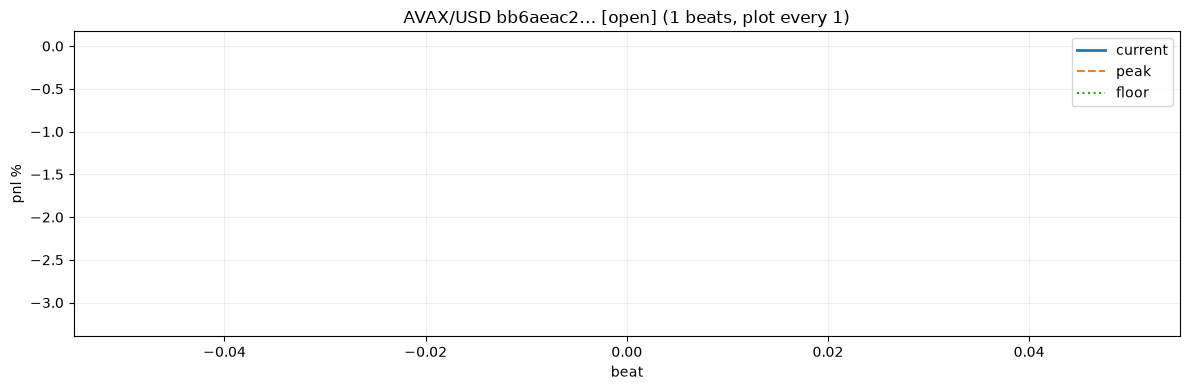

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""AVAX/USD""",1794825126159207000,0,"""CRAWL""",-3.234035,-3.234035,0.010061,"""""",0


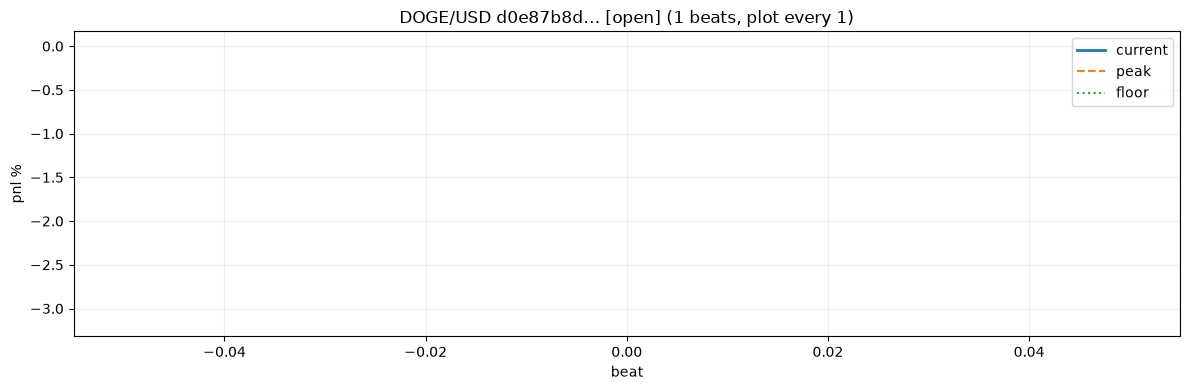

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""DOGE/USD""",1794825124137154000,0,"""CRAWL""",-3.161459,-3.161459,0.010927,"""""",0


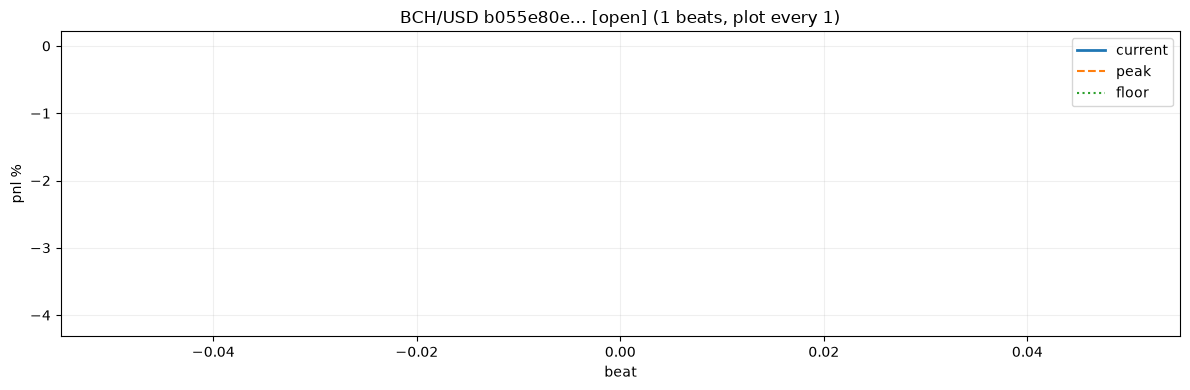

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""BCH/USD""",1794825124091320000,0,"""CRAWL""",-4.111814,-4.111814,0.010645,"""""",0


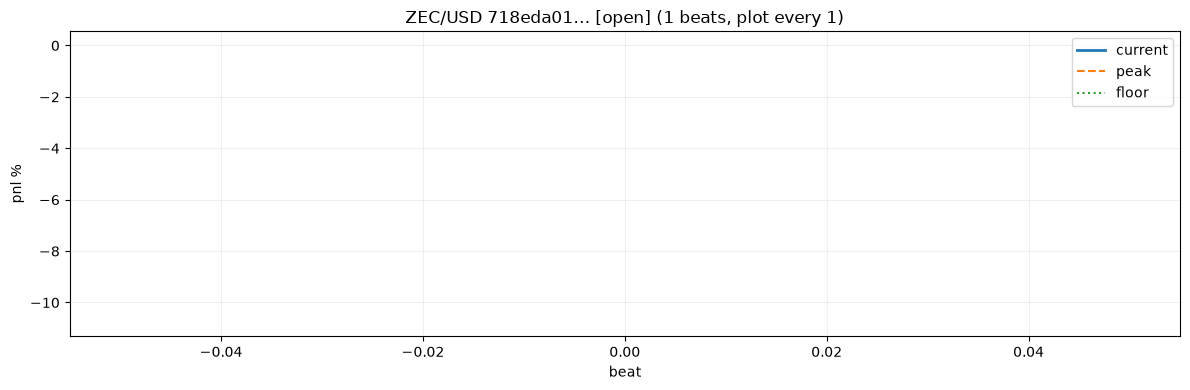

symbol,noted_at_ns,state,regime,current_pnl_pct,peak_pnl_pct,trailing_floor,trigger_reason,confirms
str,u64,i32,str,f64,f64,f64,str,i32
"""ZEC/USD""",1794825124083485000,0,"""CRAWL""",-10.783092,-10.783092,0.010358,"""""",0


In [30]:
from IPython.display import display

if not df_positions.height:
    print("tape is empty")
else:
    for row in df_positions.iter_rows(named=True):
        position_id = row["position_id"]
        traj_sql = f"""
        SELECT
            symbol,
            noted_at_ns,
            state,
            regime,
            current_pnl_pct,
            peak_pnl_pct,
            trailing_floor,
            trigger_reason,
            confirms
        FROM {STOPS_FROM}
        WHERE position_id = '{position_id}'
        ORDER BY noted_at_ns;
        """
        df_traj = con.sql(traj_sql).pl()
        if not df_traj.height:
            continue

        step = max(1, df_traj.height // 2000)
        pdf = df_traj.to_pandas().iloc[::step].reset_index(drop=True)
        pdf["t"] = range(len(pdf))

        reason = row["trigger_reason"] or "open"
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(pdf["t"], pdf["current_pnl_pct"], label="current", lw=2)
        ax.plot(pdf["t"], pdf["peak_pnl_pct"], label="peak", lw=1.5, ls="--")
        ax.plot(pdf["t"], pdf["trailing_floor"], label="floor", lw=1.5, ls=":")
        ax.set_title(
            f"{row['symbol']} {position_id[:8]}… [{reason}] "
            f"({df_traj.height} beats, plot every {step})"
        )
        ax.set_xlabel("beat (downsampled)" if step > 1 else "beat")
        ax.set_ylabel("pnl %")
        ax.legend()
        ax.grid(True, alpha=0.2)
        plt.tight_layout()
        plt.show()
        display(df_traj.tail(20))
